# 01 · Análisis exploratorio del PM2.5 de SIATA

**Fuente:** SIATA – Área Metropolitana del Valle de Aburrá, archivo `EntregaData1/Datos_SIATA_Aire_pm25.json` (PM2.5 horario, 21 estaciones, 2019-02-21 → 2020-02-20). Este cuaderno reconstruye el ETL, documenta la calidad de los datos y describe los patrones que motivan el modelo.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "font.size": 10})
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
FIG = ROOT / "reports" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
from aire.data import load_raw_json, raw_to_frames, clean_hourly, daily_means, load_stations
raw = load_raw_json(); hourly, est = raw_to_frames(raw)
valid, rep = clean_hourly(hourly); daily = daily_means(valid)
rep

{'registros_totales': 183981,
 'centinela_o_nulo': 1009,
 'bandera_calidad_mala': 3997,
 'fuera_de_rango': 1,
 'registros_validos': 178974,
 'porcentaje_validos': 97.28}

## Calidad de los datos
Se descartan centinelas (-9999), banderas de calidad SIATA > 2.5 y valores fuera de 0–500 µg/m³. Un día es válido con ≥ 18 horas (75 %, criterio de representatividad).

In [2]:
cob = daily.groupby('codigo').size().rename('dias_validos')
est.merge(cob, left_on='codigo', right_index=True)[['nombre_corto','municipio','tipo','dias_validos']].sort_values('dias_validos')

,nombre_corto,municipio,tipo,dias_validos
7,SUR-TRAF,Sabaneta,Tráfico,351
16,MED-SCRI,Medellín,Poblacional,354
15,MED-TESO,Medellín,Poblacional,355
11,MED-VILL,Medellín,Poblacional,356
5,ITA-CONC,Itagüí,Poblacional,357
0,GIR-SOSN,Girardota,Poblacional,357
4,CAL-LASA,Caldas,Poblacional,358
13,COP-CVID,Copacabana,Poblacional,358
8,CAL-JOAR,Caldas,Poblacional,358
2,MED-UNNV,Medellín,Poblacional,358


In [3]:
print('Distribución de clases (día-estación):'); print(daily['clase'].value_counts(normalize=True).round(3))
print('\nCategorías ICA:'); print(daily['categoria_ica'].value_counts())

Distribución de clases (día-estación):
clase
Aceptable    0.785
Buena        0.161
Dañina       0.054
Name: proportion, dtype: float64

Categorías ICA:
categoria_ica
Aceptable                                5909
Buena                                    1209
Dañina a la salud de grupos sensibles     371
Dañina a la salud                          36
Name: count, dtype: int64


## Estacionalidad: promedio mensual y días sobre la norma

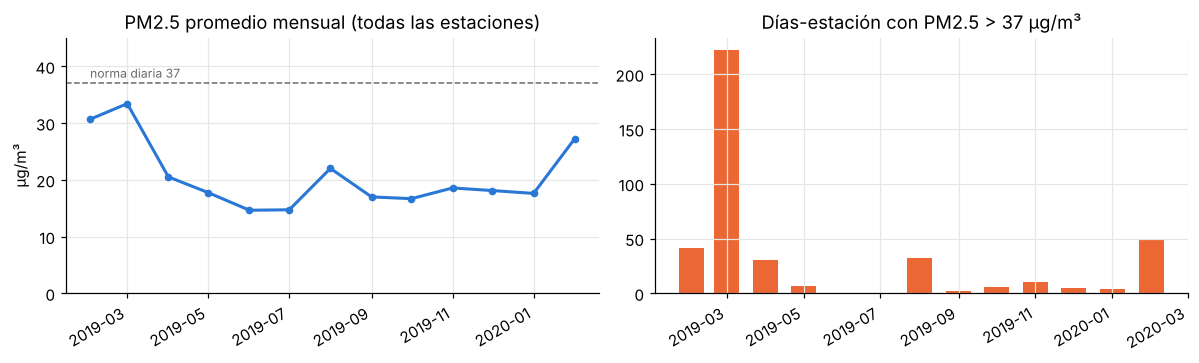

In [4]:
d = daily.copy(); d['mes'] = d['fecha'].dt.to_period('M').dt.to_timestamp()
m = d.groupby('mes').agg(media=('pm25','mean'), exced=('pm25', lambda x: (x > 37).sum()))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(m.index, m['media'], color=AZUL, lw=2, marker='o', ms=4)
ax[0].axhline(37, ls='--', color='#6b6b6b', lw=1); ax[0].text(m.index[0], 38, 'norma diaria 37', color='#6b6b6b', fontsize=8)
ax[0].set_title('PM2.5 promedio mensual (todas las estaciones)'); ax[0].set_ylabel('µg/m³'); ax[0].set_ylim(0, 45)
ax[1].bar(m.index, m['exced'], width=20, color=NARANJA)
ax[1].set_title('Días-estación con PM2.5 > 37 µg/m³'); fig.autofmt_xdate(); plt.tight_layout()
plt.savefig(FIG / 'fig1_estacionalidad.png', bbox_inches='tight'); plt.show()

Los episodios se concentran en **feb–mar 2019** (temporada de transición) y reaparecen en **feb 2020**; también aparece un pico en **agosto de 2019** (16-ago: 84 % de estaciones sobre la norma).

In [5]:
dow = d.groupby(d['fecha'].dt.dayofweek)['pm25'].mean(); dow.index = ['lun','mar','mié','jue','vie','sáb','dom']
est_m = d.merge(est[['codigo','nombre_corto','tipo']], on='codigo').groupby(['nombre_corto','tipo'])['pm25'].mean().sort_values()
print(dow.round(1)); print(est_m.round(1))

lun    18.2
mar    20.1
mié    21.1
jue    21.1
vie    21.7
sáb    19.9
dom    17.4
Name: pm25, dtype: float64
nombre_corto  tipo       
BAR-TORR      Poblacional    13.8
BEL-FEVE      Poblacional    15.6
COP-CVID      Poblacional    15.6
MED-SCRI      Poblacional    16.1
MED-TESO      Poblacional    17.1
ENV-HOSP      Poblacional    17.2
EST-HOSP      Poblacional    18.2
SAB-RAME      Poblacional    18.4
ITA-CONC      Poblacional    18.4
MED-UNNV      Poblacional    18.6
MED-LAYE      Poblacional    18.9
MED-VILL      Poblacional    19.0
GIR-SOSN      Poblacional    19.1
CAL-LASA      Poblacional    20.7
CAL-JOAR      Poblacional    21.3
MED-BEME      Poblacional    22.1
MED-ARAN      Poblacional    22.3
MED-ALTA      Poblacional    22.7
ITA-CJUS      Poblacional    24.0
CEN-TRAF      Tráfico        28.1
SUR-TRAF      Tráfico        31.4
Name: pm25, dtype: float64


## Persistencia: autocorrelación del PM2.5 diario
La fuerte autocorrelación justifica un modelo de estados con memoria (HMM) y explica por qué la persistencia es una línea base difícil de superar.

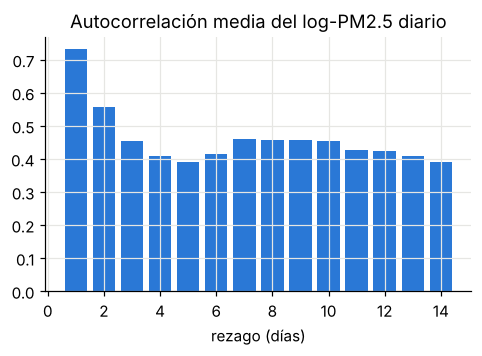

[np.float64(0.73), np.float64(0.56), np.float64(0.45)]


In [6]:
from aire.data import daily_wide
w = daily_wide(); lags = range(1, 15)
ac = [np.nanmean([w[c].autocorr(l) for c in w.columns]) for l in lags]
plt.figure(figsize=(5,3)); plt.bar(list(lags), ac, color=AZUL); plt.title('Autocorrelación media del log-PM2.5 diario'); plt.xlabel('rezago (días)'); plt.show()
print([round(a,2) for a in ac[:3]])